#### Ridge Lasso Elasticnet Regression practicle 

In [112]:
# 1. Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns


In [113]:
# Load Csv..
df = pd.read_csv('Algerian_forest_fires_dataset_UPDATE.csv',header=1)
df.head()


,day,month,year,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes
0,01,06,2012,29,57,18,0,65.7,3.4,7.6,1.3,3.4,0.5,not fire
1,02,06,2012,29,61,13,1.3,64.4,4.1,7.6,1,3.9,0.4,not fire
2,03,06,2012,26,82,22,13.1,47.1,2.5,7.1,0.3,2.7,0.1,not fire
3,04,06,2012,25,89,13,2.5,28.6,1.3,6.9,0,1.7,0,not fire
4,05,06,2012,27,77,16,0,64.8,3,14.2,1.2,3.9,0.5,not fire


##### 1. Data Cleaning

In [114]:
# Get info. about data..
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 246 entries, 0 to 245
Data columns (total 14 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   day          246 non-null    object
 1   month        245 non-null    object
 2   year         245 non-null    object
 3   Temperature  245 non-null    object
 4    RH          245 non-null    object
 5    Ws          245 non-null    object
 6   Rain         245 non-null    object
 7   FFMC         245 non-null    object
 8   DMC          245 non-null    object
 9   DC           245 non-null    object
 10  ISI          245 non-null    object
 11  BUI          245 non-null    object
 12  FWI          245 non-null    object
 13  Classes      244 non-null    object
dtypes: object(14)
memory usage: 27.0+ KB


In [115]:
#Check null values
df[df.isnull().any(axis=1)]

,day,month,year,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes
122,Sidi-Bel Abbes Region Dataset,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
167,14,07,2012,37,37,18,0.2,88.9,12.9,14.6 9,12.5,10.4,fire,NaN


In [116]:
# create column country and divide dataset based on country 
df.loc[:122,'Region'] = 0
df.loc[122:,'Region'] =1

In [117]:
# Drop null value..
df = df.dropna().reset_index(drop=True)

In [118]:
# Convert Region in intiger..
df['Region'] = df['Region'].astype('Int64')

In [119]:
df.iloc[[122]]
df = df.drop(122).reset_index(drop=True)


In [120]:
df.head()

,day,month,year,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes,Region
0,01,06,2012,29,57,18,0,65.7,3.4,7.6,1.3,3.4,0.5,not fire,0
1,02,06,2012,29,61,13,1.3,64.4,4.1,7.6,1,3.9,0.4,not fire,0
2,03,06,2012,26,82,22,13.1,47.1,2.5,7.1,0.3,2.7,0.1,not fire,0
3,04,06,2012,25,89,13,2.5,28.6,1.3,6.9,0,1.7,0,not fire,0
4,05,06,2012,27,77,16,0,64.8,3,14.2,1.2,3.9,0.5,not fire,0


In [121]:
df.columns

Index(['day', 'month', 'year', 'Temperature', ' RH', ' Ws', 'Rain ', 'FFMC',
       'DMC', 'DC', 'ISI', 'BUI', 'FWI', 'Classes  ', 'Region'],
      dtype='object')

In [122]:
# convert in integer for integer column
df[['day', 'month', 'year', 'Temperature', ' RH', ' Ws']] = df[['day', 'month', 'year', 'Temperature', ' RH', ' Ws']].astype('int64')
# convert in float for float columns
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 243 entries, 0 to 242
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   day          243 non-null    int64 
 1   month        243 non-null    int64 
 2   year         243 non-null    int64 
 3   Temperature  243 non-null    int64 
 4    RH          243 non-null    int64 
 5    Ws          243 non-null    int64 
 6   Rain         243 non-null    object
 7   FFMC         243 non-null    object
 8   DMC          243 non-null    object
 9   DC           243 non-null    object
 10  ISI          243 non-null    object
 11  BUI          243 non-null    object
 12  FWI          243 non-null    object
 13  Classes      243 non-null    object
 14  Region       243 non-null    Int64 
dtypes: Int64(1), int64(6), object(8)
memory usage: 28.8+ KB


In [123]:
df[['Rain ', 'FFMC','DMC', 'DC', 'ISI', 'BUI', 'FWI']] = df[['Rain ', 'FFMC','DMC', 'DC', 'ISI', 'BUI', 'FWI']].astype('Float64')

In [124]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 243 entries, 0 to 242
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   day          243 non-null    int64  
 1   month        243 non-null    int64  
 2   year         243 non-null    int64  
 3   Temperature  243 non-null    int64  
 4    RH          243 non-null    int64  
 5    Ws          243 non-null    int64  
 6   Rain         243 non-null    Float64
 7   FFMC         243 non-null    Float64
 8   DMC          243 non-null    Float64
 9   DC           243 non-null    Float64
 10  ISI          243 non-null    Float64
 11  BUI          243 non-null    Float64
 12  FWI          243 non-null    Float64
 13  Classes      243 non-null    object 
 14  Region       243 non-null    Int64  
dtypes: Float64(7), Int64(1), int64(6), object(1)
memory usage: 30.5+ KB


In [125]:
# Remove white space in columns name 
df.columns = df.columns.str.strip()
df.columns

Index(['day', 'month', 'year', 'Temperature', 'RH', 'Ws', 'Rain', 'FFMC',
       'DMC', 'DC', 'ISI', 'BUI', 'FWI', 'Classes', 'Region'],
      dtype='object')

In [126]:
# standrize text 
obj_col = df.select_dtypes(include=['object'])

for col in obj_col:
    df[col] = df[col].str.lower()
    df[col] = df[col].str.strip()

In [127]:
df.head()

,day,month,year,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes,Region
0,1,6,2012,29,57,18,0.0,65.7,3.4,7.6,1.3,3.4,0.5,not fire,0
1,2,6,2012,29,61,13,1.3,64.4,4.1,7.6,1.0,3.9,0.4,not fire,0
2,3,6,2012,26,82,22,13.1,47.1,2.5,7.1,0.3,2.7,0.1,not fire,0
3,4,6,2012,25,89,13,2.5,28.6,1.3,6.9,0.0,1.7,0.0,not fire,0
4,5,6,2012,27,77,16,0.0,64.8,3.0,14.2,1.2,3.9,0.5,not fire,0


In [128]:
df['Classes'].value_counts()

Classes
fire        137
not fire    106
Name: count, dtype: int64

In [129]:
df.head()

,day,month,year,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes,Region
0,1,6,2012,29,57,18,0.0,65.7,3.4,7.6,1.3,3.4,0.5,not fire,0
1,2,6,2012,29,61,13,1.3,64.4,4.1,7.6,1.0,3.9,0.4,not fire,0
2,3,6,2012,26,82,22,13.1,47.1,2.5,7.1,0.3,2.7,0.1,not fire,0
3,4,6,2012,25,89,13,2.5,28.6,1.3,6.9,0.0,1.7,0.0,not fire,0
4,5,6,2012,27,77,16,0.0,64.8,3.0,14.2,1.2,3.9,0.5,not fire,0


##### EDA

In [130]:
## Basic data overview
print(df.head())
print(df.shape)
print(df.info())


   day  month  year  Temperature  RH  Ws  Rain  FFMC  DMC    DC  ISI  BUI  \
0    1      6  2012           29  57  18   0.0  65.7  3.4   7.6  1.3  3.4   
1    2      6  2012           29  61  13   1.3  64.4  4.1   7.6  1.0  3.9   
2    3      6  2012           26  82  22  13.1  47.1  2.5   7.1  0.3  2.7   
3    4      6  2012           25  89  13   2.5  28.6  1.3   6.9  0.0  1.7   
4    5      6  2012           27  77  16   0.0  64.8  3.0  14.2  1.2  3.9   

   FWI   Classes  Region  
0  0.5  not fire       0  
1  0.4  not fire       0  
2  0.1  not fire       0  
3  0.0  not fire       0  
4  0.5  not fire       0  
(243, 15)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 243 entries, 0 to 242
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   day          243 non-null    int64  
 1   month        243 non-null    int64  
 2   year         243 non-null    int64  
 3   Temperature  243 non-null    int64  
 4   RH 

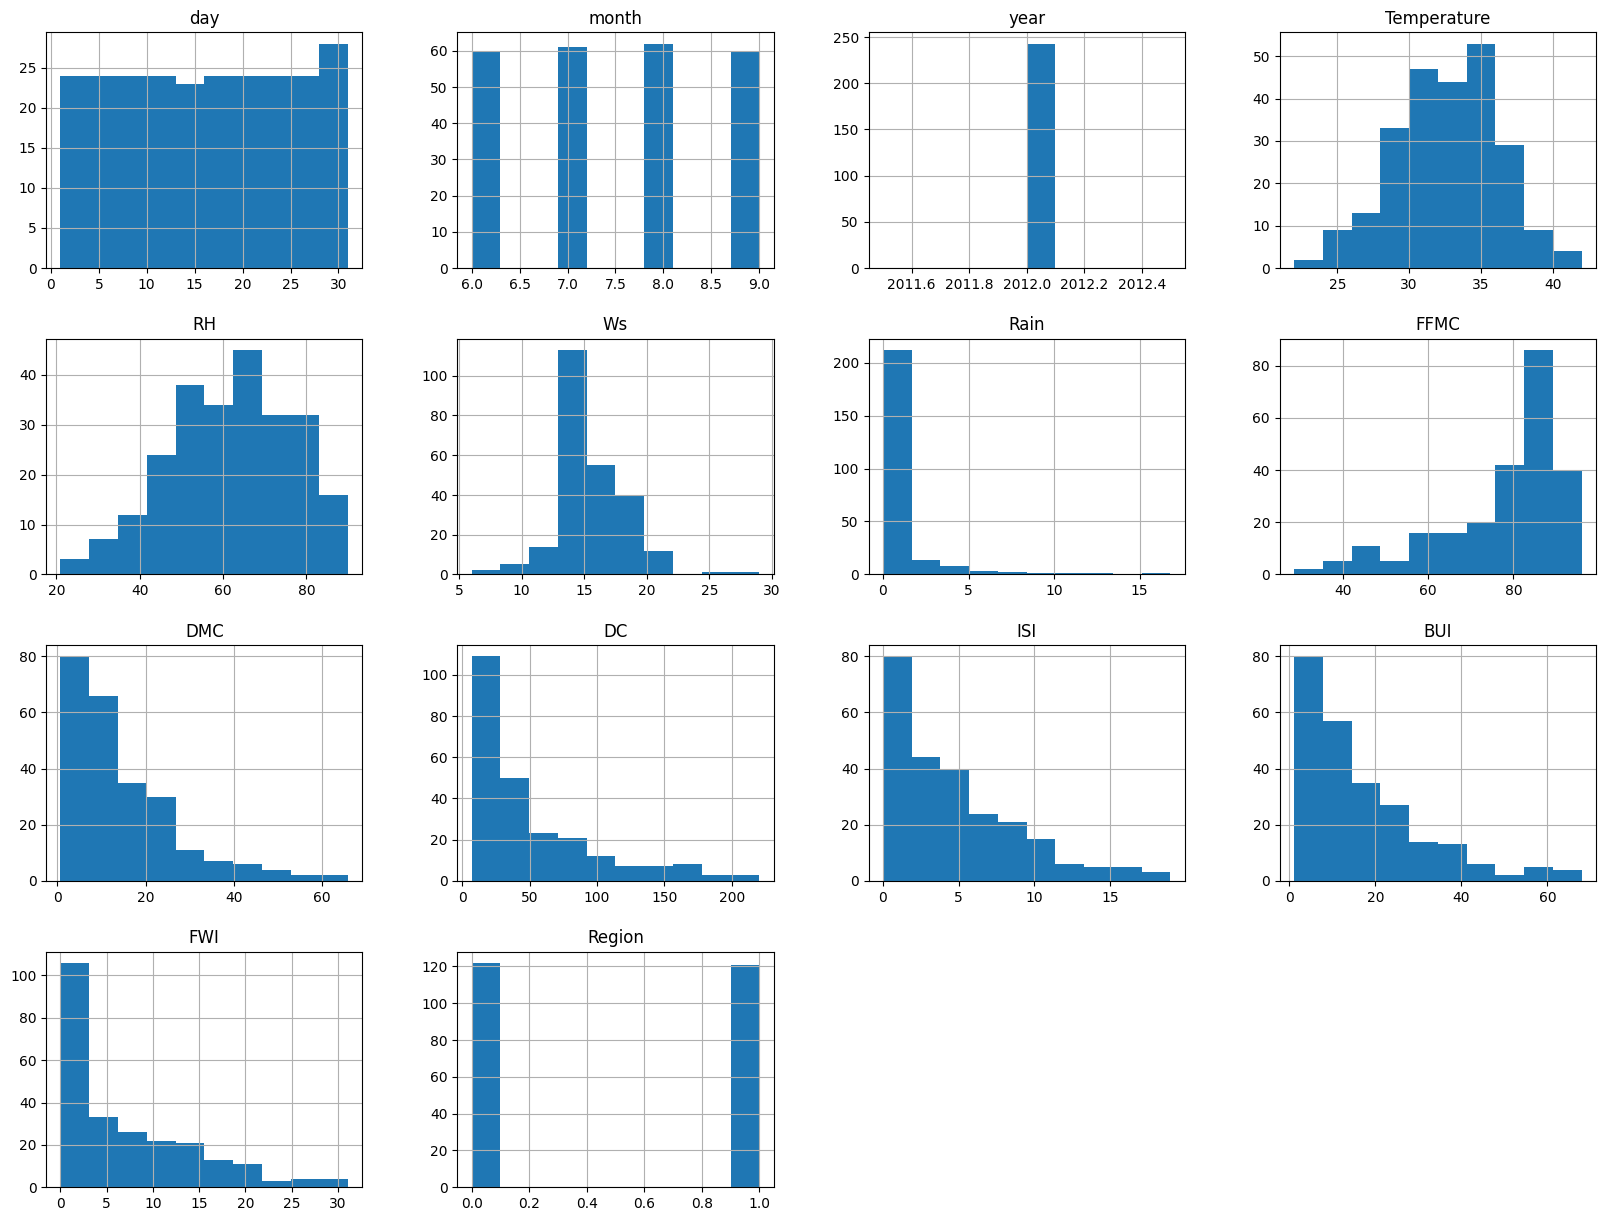

In [131]:
# find the distributio of data...
df.hist(bins=10,figsize=(20,15))
plt.show()

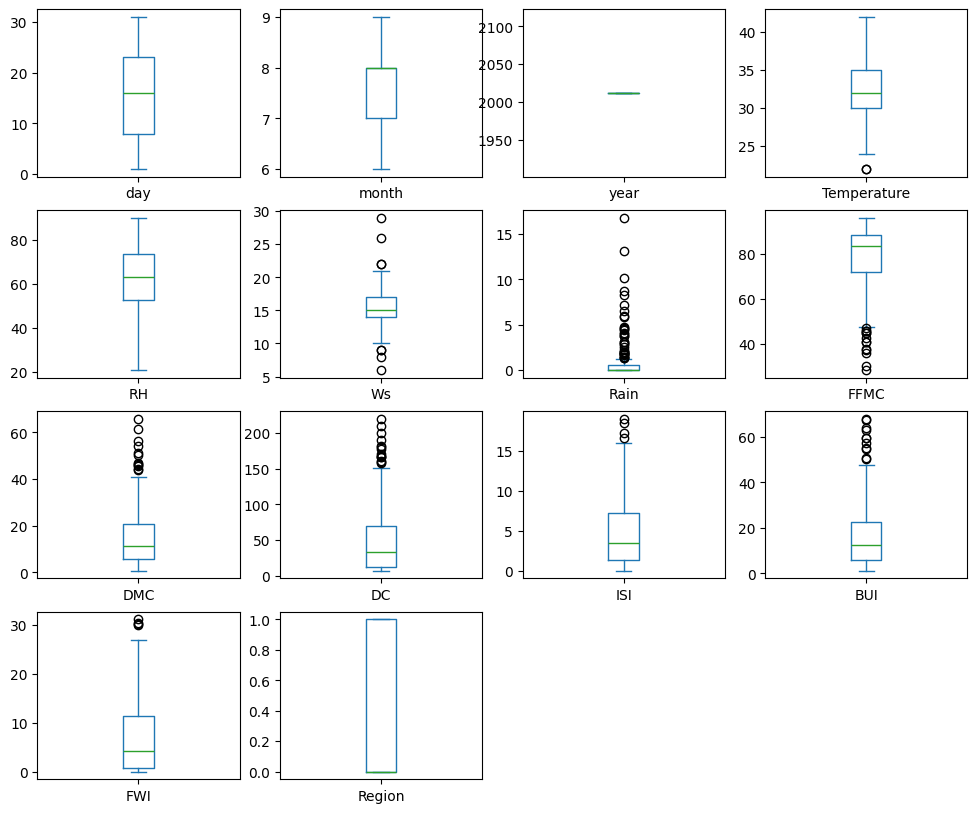

In [132]:
# box lot to find 5 number of summary...
df.plot(kind='box', subplots=True, layout=(4,4), figsize=(12,10))
plt.show()

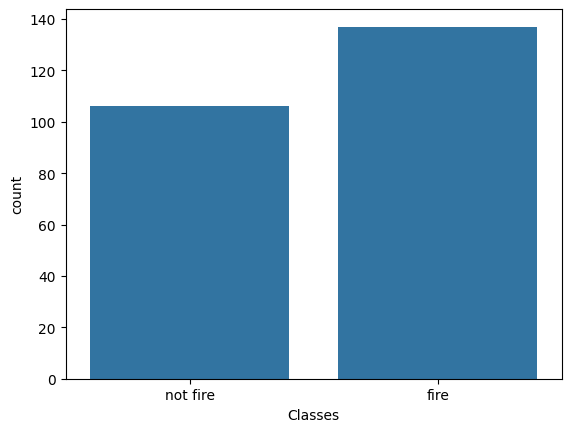

In [133]:
# Countplot :- used when we have categorical feature
sns.countplot(x=df['Classes'])
plt.show()


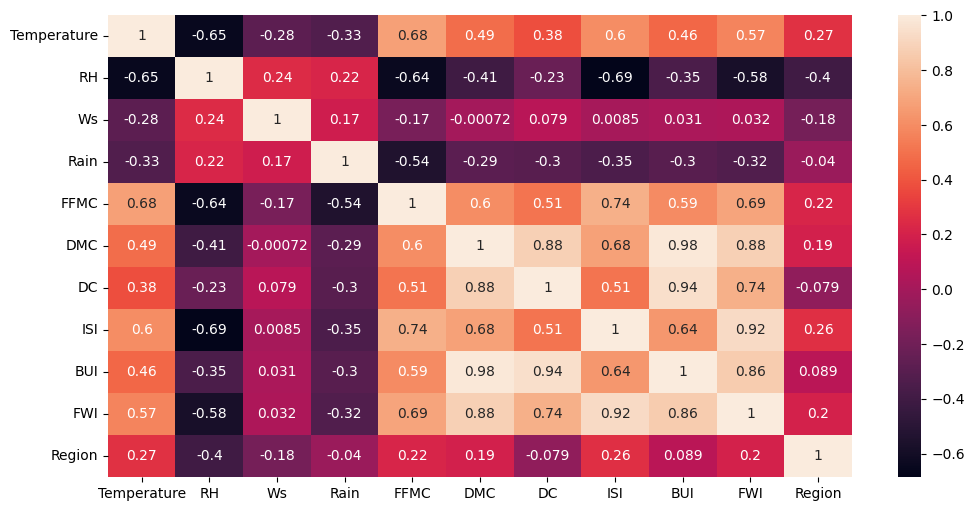

In [134]:
# relationship betwwen features
plt.figure(figsize=(12,6))
num_col = df[['Temperature', 'RH', 'Ws', 'Rain', 'FFMC',
       'DMC', 'DC', 'ISI', 'BUI', 'FWI','Region']]
sns.heatmap(num_col.corr(),annot=True)
plt.show()

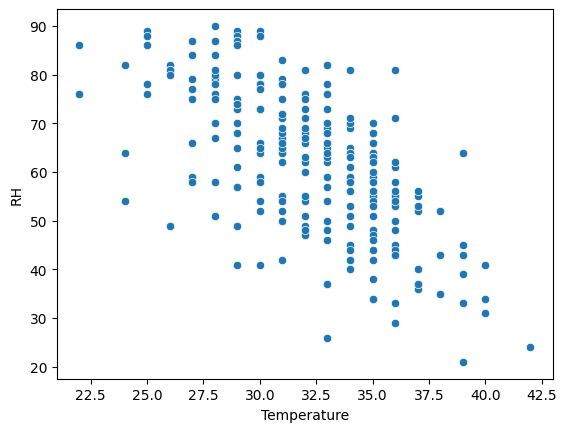

In [135]:
# Scatter Plot
sns.scatterplot(x='Temperature', y='RH', data=df)
plt.show()

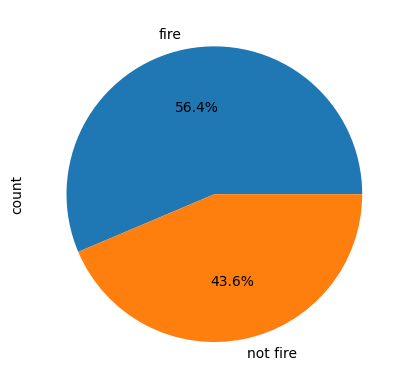

In [136]:
df['Classes'].value_counts().plot.pie(autopct='%1.1f%%')
plt.show()

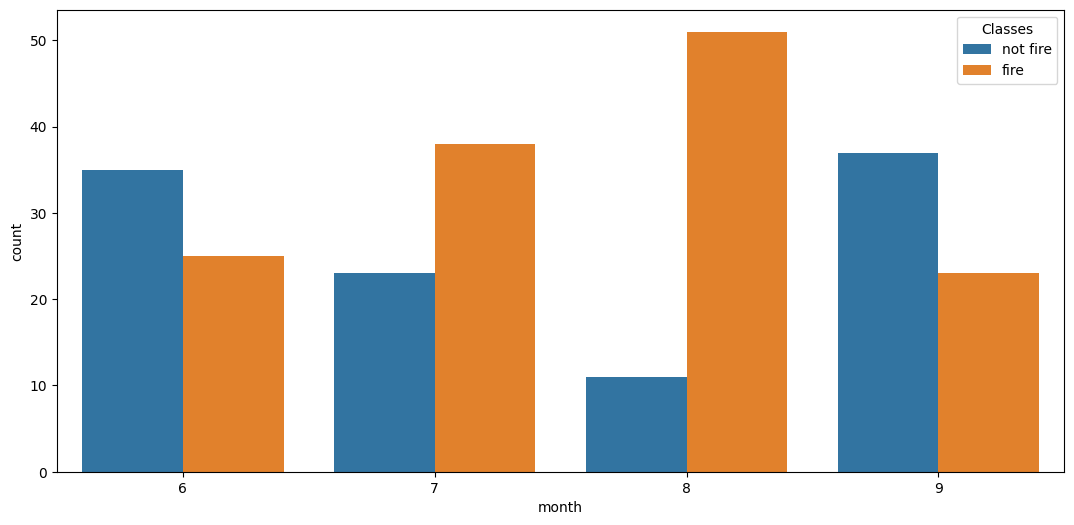

In [137]:
# Check monthly fire 
plt.subplots(figsize=(13,6))
sns.countplot(x='month',hue='Classes',data=df)
plt.show()

#### Model Traninig part

In [138]:
# see data
df.head()

,day,month,year,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes,Region
0,1,6,2012,29,57,18,0.0,65.7,3.4,7.6,1.3,3.4,0.5,not fire,0
1,2,6,2012,29,61,13,1.3,64.4,4.1,7.6,1.0,3.9,0.4,not fire,0
2,3,6,2012,26,82,22,13.1,47.1,2.5,7.1,0.3,2.7,0.1,not fire,0
3,4,6,2012,25,89,13,2.5,28.6,1.3,6.9,0.0,1.7,0.0,not fire,0
4,5,6,2012,27,77,16,0.0,64.8,3.0,14.2,1.2,3.9,0.5,not fire,0


In [139]:
# drop useless column
df.drop(['day','month','year'],axis=1,inplace=True)

In [140]:
df.head()
df.tail()

,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes,Region
238,30,65,14,0.0,85.4,16.0,44.5,4.5,16.9,6.5,fire,1
239,28,87,15,4.4,41.1,6.5,8.0,0.1,6.2,0.0,not fire,1
240,27,87,29,0.5,45.9,3.5,7.9,0.4,3.4,0.2,not fire,1
241,24,54,18,0.1,79.7,4.3,15.2,1.7,5.1,0.7,not fire,1
242,24,64,15,0.2,67.3,3.8,16.5,1.2,4.8,0.5,not fire,1


In [141]:
# encode classes
df['Classes'] = np.where(df['Classes']=='fire',1,0)


In [142]:
# Define dependent and independent feature
x = df.drop('FWI',axis=1)
y= df['FWI']

In [143]:
# train test split
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.25,random_state=42)
x_train.shape,x_test.shape

((182, 11), (61, 11))

In [144]:
## Feature Selection based on correlaltion . this is only production purpose not practice it just copy paste 😁
def correlation(dataset, threshold):
    col_corr = set()
    corr_matrix = dataset.corr()
    for i in range(len(corr_matrix.columns)):
        for j in range(i):
            if abs(corr_matrix.iloc[i, j]) > threshold: 
                colname = corr_matrix.columns[i]
                col_corr.add(colname)
    return col_corr
corr_features = correlation(x_train,0.85)

In [145]:
## drop features when correlation is more than 0.85 
x_train.drop(corr_features,axis=1,inplace=True)
x_test.drop(corr_features,axis=1,inplace=True)
x_train.shape,x_test.shape

((182, 9), (61, 9))

##### Feature Scaling 

In [146]:
from sklearn.preprocessing import StandardScaler
scaller = StandardScaler()
x_train_scaled = scaller.fit_transform(x_train)
x_test_Scaled = scaller.transform(x_test)


##### Box plot to see the effect of scalling.

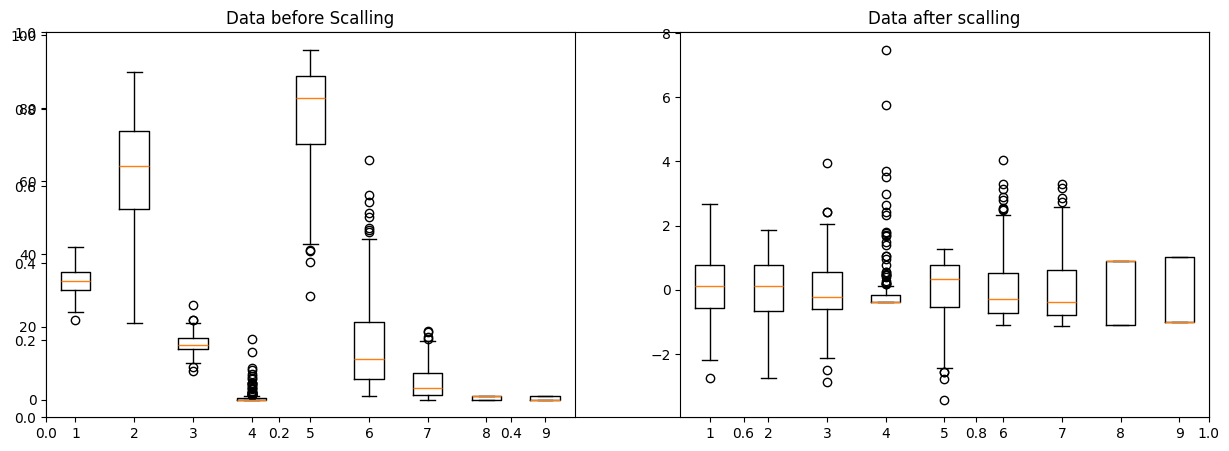

In [147]:
plt.subplots(figsize=(15, 5))
plt.subplot(1, 2, 1)
plt.boxplot(x=x_train)
plt.title("Data before Scalling")
plt.subplot(1,2,2)
plt.boxplot(x=x_train_scaled)
plt.title("Data after scalling")
plt.show()

# Conclusion :- After data are on same scalled....

##### Linear Regression Model..

______model Accuracy______
mean aboslute error : 0.546823646524997
model score : 98.47657384266951%


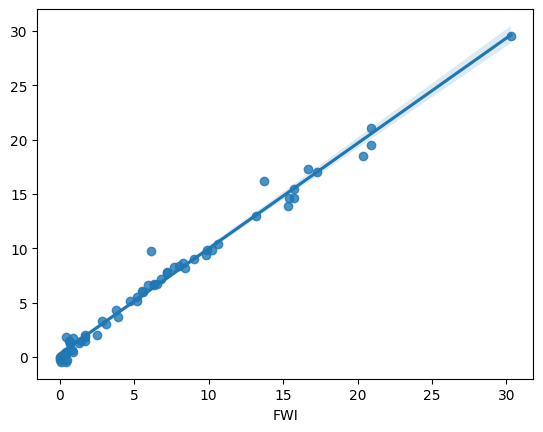

In [148]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error,r2_score
linear_model = LinearRegression()
linear_model.fit(x_train_scaled,y_train)
y_pred = linear_model.predict(x_test_Scaled)
mea = mean_absolute_error(y_test,y_pred)
score = r2_score(y_test,y_pred)
print("______model Accuracy______")
print(f"mean aboslute error : {mea}")
print(f"model score : {score*100}%")

####
sns.regplot(x=y_test, y = y_pred)
plt.show()


##### Lasso Regression..

______model Accuracy______
mean aboslute error : 1.1331759949144087
model score : 94.92020263112389%


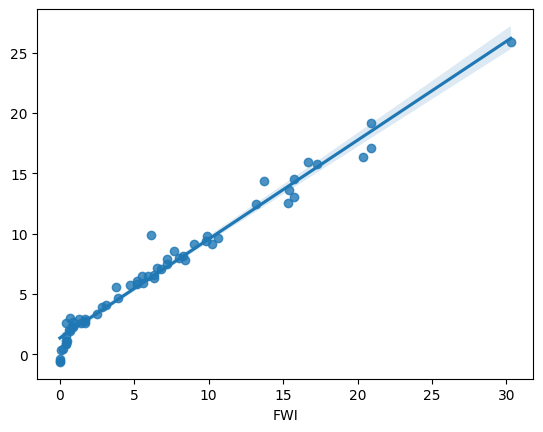

In [149]:
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_absolute_error,r2_score
Lasso_model = Lasso()
Lasso_model.fit(x_train_scaled,y_train)
y_pred = Lasso_model.predict(x_test_Scaled)
mea = mean_absolute_error(y_test,y_pred)
score = r2_score(y_test,y_pred)
print("______model Accuracy______")
print(f"mean aboslute error : {mea}")
print(f"model score : {score*100}%")

####
sns.regplot(x=y_test, y = y_pred)
plt.show()


##### Ridge Regression..

______model Accuracy______
mean aboslute error : 0.5642305340107385
model score : 98.42993364555473%


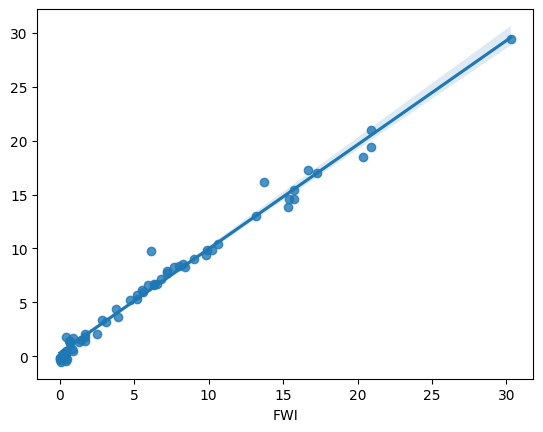

In [150]:
from sklearn.linear_model import RidgeCV
from sklearn.metrics import mean_absolute_error,r2_score
RidgeCv_model = RidgeCV()
RidgeCv_model.fit(x_train_scaled,y_train)
y_pred = RidgeCv_model.predict(x_test_Scaled)
mea = mean_absolute_error(y_test,y_pred)
score = r2_score(y_test,y_pred)
print("______model Accuracy______")
print(f"mean aboslute error : {mea}")
print(f"model score : {score*100}%")

####
sns.regplot(x=y_test, y = y_pred)
plt.show()


##### ElasticNet...

______model Accuracy______
mean aboslute error : 1.8822353634895996
model score : 87.53460589519703%


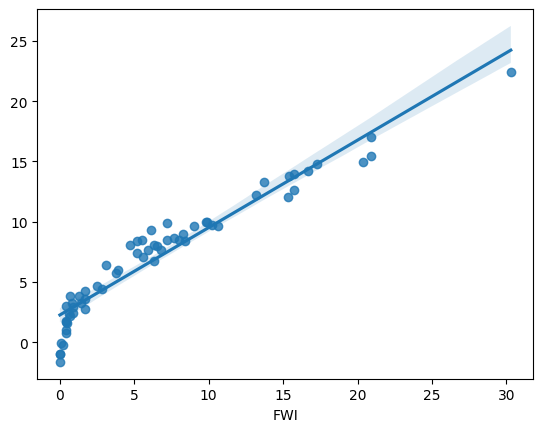

In [151]:
from sklearn.linear_model import ElasticNet
from sklearn.metrics import mean_absolute_error,r2_score
Elastic_model = ElasticNet()
Elastic_model.fit(x_train_scaled,y_train)
y_pred = Elastic_model.predict(x_test_Scaled)
mea = mean_absolute_error(y_test,y_pred)
score = r2_score(y_test,y_pred)
print("______model Accuracy______")
print(f"mean aboslute error : {mea}")
print(f"model score : {score*100}%")

####
sns.regplot(x=y_test, y = y_pred)
plt.show()


##### Elastic Net CV...

______model Accuracy______
mean aboslute error : 0.6575946731430902
model score : 98.14217587854941%


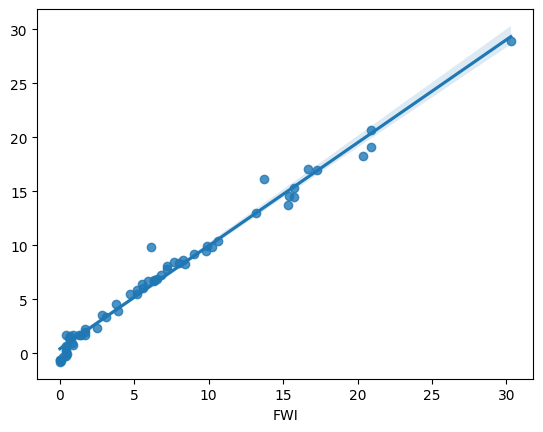

In [152]:
from sklearn.linear_model import ElasticNetCV
from sklearn.metrics import mean_absolute_error,r2_score
Elaasticv_model = ElasticNetCV()
Elaasticv_model.fit(x_train_scaled,y_train)
y_pred = Elaasticv_model.predict(x_test_Scaled)
mea = mean_absolute_error(y_test,y_pred)
score = r2_score(y_test,y_pred)
print("______model Accuracy______")
print(f"mean aboslute error : {mea}")
print(f"model score : {score*100}%")

####
sns.regplot(x=y_test, y = y_pred)
plt.show()


In [153]:
x.head()

,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,Classes,Region
0,29,57,18,0.0,65.7,3.4,7.6,1.3,3.4,0,0
1,29,61,13,1.3,64.4,4.1,7.6,1.0,3.9,0,0
2,26,82,22,13.1,47.1,2.5,7.1,0.3,2.7,0,0
3,25,89,13,2.5,28.6,1.3,6.9,0.0,1.7,0,0
4,27,77,16,0.0,64.8,3.0,14.2,1.2,3.9,0,0


In [154]:
x_train.head(),y

(     Temperature  RH  Ws  Rain  FFMC   DMC   ISI  Classes  Region
 97            29  74  19   0.1  75.8   3.6   2.1        0       0
 141           31  72  14   0.2  60.2   3.8   0.8        0       1
 192           40  31  15   0.0  94.2  22.5  16.6        1       1
 68            32  60  18   0.3  77.1  11.3   2.2        0       0
 119           32  47  14   0.7  77.5   7.1   1.8        0       0,
 0      0.5
 1      0.4
 2      0.1
 3      0.0
 4      0.5
       ... 
 238    6.5
 239    0.0
 240    0.2
 241    0.7
 242    0.5
 Name: FWI, Length: 243, dtype: Float64)

In [155]:
def prediction(value):
    pred = linear_model.predict(scaller.transform(value))
    
    labels = {0: "No Fire", 1: "Fire"}
    category = labels[int(pred[0] > 0.5)]
    
    return category
prediction([[29,57,18,0.0,65.7,3.4,1.3,0,0]])

c:\Users\shali\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


'Fire'